# 01 - Data audit (Day 1)
Audit the attrition data **before** any model exists. Run top to bottom from a clean kernel.

**Rule:** finish and commit this audit first; only then open the files in `04_Validation_Vault` (see `reports/vault_comparison_cx01.md`).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50); pd.set_option('display.max_colwidth', 120)
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs

## 1. Load `attrition_dataset`: shape, columns, types, first 5 rows

In [2]:
raw = D.load_attrition()
print('shape:', raw.shape)
print(list(raw.columns))
raw.dtypes.to_frame('dtype')

shape: (2389, 42)
['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount']


                                          dtype
row_id                                    int64
employee_id                                 str
observation_date                 datetime64[us]
department_id                               str
role_id                                     str
job_level                                 int64
work_location                               str
work_mode                                   str
employment_type                             str
highest_education                           str
tenure_months                             int64
total_experience_years                  float64
previous_employers_count                  int64
commute_distance_km                     float64
annual_fixed_pay                          int64
comp_ratio                              float64
raises_received                           int64
last_raise_pct                          float64
months_since_last_raise                   int64
promotions_received                     

In [3]:
raw.head()

   row_id employee_id observation_date department_id role_id  job_level work_location work_mode employment_type              highest_education  tenure_months  total_experience_years  \
0       1    EMP-0002       2025-09-30           D08    R047          4          Pune    Remote       Permanent          B.E. Computer Science            164                    30.8   
1       2    EMP-0004       2025-09-30           D03    R017          3         Erode    Hybrid       Permanent                            MCA            162                    17.5   
2       3    EMP-0011       2025-09-30           D07    R039          1         Kochi    Hybrid       Permanent               M.A. Social Work            154                    12.8   
3       4    EMP-0012       2025-09-30           D01    R004          2       Chennai    Onsite       Permanent  B.Tech Information Technology            152                    17.2   
4       5    EMP-0013       2025-09-30           D04    R023          2    

**One row** = one employee at one observation date (a snapshot of their features). **Target `left_within_12m`** = 1 if that employee left within 12 months after `observation_date`, else 0.

## 2. Schema and data-quality inventory

In [4]:
A.schema_inventory(raw)

                             column           dtype  non_null  missing  missing_pct  n_unique                   example
0                            row_id           int64      2389        0         0.00      2389                         1
1                       employee_id             str      2389        0         0.00      2383                  EMP-0002
2                  observation_date  datetime64[us]      2389        0         0.00      1135       2025-09-30 00:00:00
3                     department_id             str      2389        0         0.00        10                       D08
4                           role_id             str      2389        0         0.00        48                      R047
5                         job_level           int64      2389        0         0.00         6                         4
6                     work_location             str      2389        0         0.00        16                      Pune
7                         work_mode     

## 3. Missing values

In [5]:
A.missingness(raw)

                         column  missing  missing_pct
0              resignation_date     2068        86.56
1                     exit_date     2040        85.39
2                   exit_reason     2040        85.39
3         fnf_settlement_amount     2040        85.39
4           exit_interview_done     2040        85.39
5   months_since_last_promotion     1459        61.07
6         last_engagement_score      528        22.10
7                last_raise_pct      202         8.46
8       last_performance_rating      182         7.62
9           commute_distance_km       55         2.30
10            highest_education       15         0.63

## 4. Duplicates

In [6]:
A.duplicates(raw)

{'exact_duplicate_rows': 6, 'duplicate_ids_extra_rows': 6, 'ids_affected': ['EMP-0060', 'EMP-0237', 'EMP-0238', 'EMP-0325', 'EMP-0483', 'EMP-0570']}

## 5. Impossible values (negative tenure, percentages above 100, ...)
There is no `age` column in this table, so 'age under 18' cannot be tested here.

In [7]:
A.impossible_values(raw)

                                        rule                                columns  rows                                         row_ids
0                            negative tenure                          tenure_months     4                            [109, 126, 313, 340]
1                  negative total experience                 total_experience_years    10  [517, 872, 1106, 1651, 1815, 1819, 1946, 2155]
2             experience shorter than tenure  total_experience_years, tenure_months   140        [384, 473, 502, 528, 538, 553, 563, 565]
3              attendance_rate_3m above 100%                     attendance_rate_3m     2                                     [431, 1234]
4                attendance_rate_3m below 0%                     attendance_rate_3m     0                                              []
5                    wfh_share_3m above 100%                           wfh_share_3m    23       [660, 672, 695, 713, 831, 883, 991, 1238]
6                      wfh_share_3

## 6. Outliers: IQR rule and Z-score
Outliers are **investigation candidates, not automatic errors**: a very high salary can be a real senior person.

In [8]:
iq = A.iqr_outliers(raw); zs = A.zscore_outliers(raw)
iq.sort_values('iqr_outliers', ascending=False).head(10)

                             column           q1            q3         lower         upper  iqr_outliers
19  avg_overtime_hours_per_month_3m       0.0000  0.000000e+00       0.00000  0.000000e+00           446
12               internal_transfers       0.0000  0.000000e+00       0.00000  0.000000e+00           189
4               commute_distance_km       6.2000  1.557500e+01      -7.86250  2.963750e+01           141
10              promotions_received       0.0000  1.000000e+00      -1.50000  2.500000e+00           138
0                         job_level       2.0000  3.000000e+00       0.50000  4.500000e+00           126
16               training_hours_12m      14.4000  3.320000e+01     -13.80000  6.140000e+01            99
5                  annual_fixed_pay  445848.0000  1.404108e+06 -991542.00000  2.841498e+06            94
24    dept_attrition_rate_prior_12m       0.1273  1.816000e-01       0.04585  2.630500e-01            87
1                     tenure_months      18.0000  5.100

In [9]:
zs.sort_values('z_outliers_abs_gt_3', ascending=False).head(10)

                             column       mean        std  z_outliers_abs_gt_3  max_abs_z
12               internal_transfers   0.082880   0.289042                  189   6.632668
15              manager_changes_12m   0.310172   0.560737                   97   8.363691
19  avg_overtime_hours_per_month_3m   2.168690   5.333035                   61   8.968872
10              promotions_received   0.629552   0.983572                   50   6.476847
4               commute_distance_km  12.413839   9.354767                   47   5.621322
16               training_hours_12m  26.317204  17.427778                   47   6.523080
18                 late_arrivals_3m   4.971955   3.929854                   45   6.114234
1                     tenure_months  37.776476  27.424043                   42   4.602659
24    dept_attrition_rate_prior_12m   0.152027   0.046876                   40   3.243138
22             unpaid_leave_days_6m   1.409167   1.428979                   36   7.411471

In [10]:
A.pay_consistency_outliers(raw)  # salary typos: pay / comp_ratio should be ~constant inside a role

     row_id employee_id role_id  annual_fixed_pay  comp_ratio  ratio_to_role_midpoint
14       15    EMP-0034    R015           4888200       0.966                   11.37
216     217    EMP-0433    R006          18671760       1.279                   11.11
344     345    EMP-0601    R034           3606000       0.975                   11.11

## 7. Class imbalance and the majority-class trap

{'rows': 2389, 'stayed': 2040, 'left': 349, 'attrition_pct': 14.61, 'majority_accuracy_pct': 85.39, 'majority_recall_for_leavers': 0.0}
Always predicting 'stay' is 85.39% accurate but finds 0 of 349 leavers.


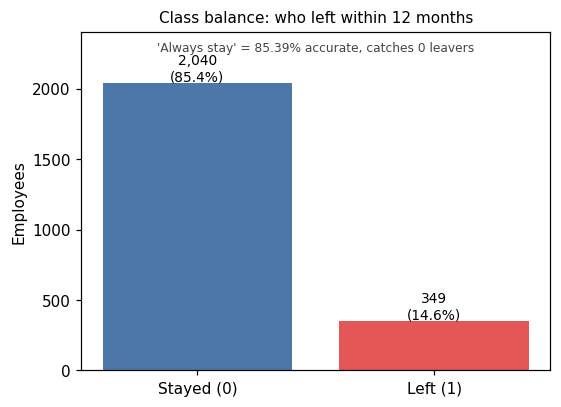

In [11]:
cb = A.class_balance(raw); print(cb)
print(f"Always predicting 'stay' is {cb['majority_accuracy_pct']}% accurate but finds 0 of {cb['left']} leavers.")
A.plot_class_balance(cb);

## 8. Leakage hunt: prove each suspect

In [12]:
post = [c for c in C.LEAKAGE_CONFIRMED if c != 'voluntary_left_within_12m']
A.missingness_indicator_power(raw, post)

                  column  filled_in_flag_auc  filled_when_left_pct  filled_when_stayed_pct
0              exit_date              1.0000                 100.0                     0.0
1       resignation_date              0.9599                  92.0                     0.0
2            exit_reason              1.0000                 100.0                     0.0
3    exit_interview_done              1.0000                 100.0                     0.0
4  fnf_settlement_amount              1.0000                 100.0                     0.0

In [13]:
lk = A.leakage_review(raw); lk[['column', 'verdict', 'evidence']]

                      column               verdict                                                                                                                 evidence
0                  exit_date     CONFIRMED LEAKAGE  filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0); every non-null date is after observation_...
1           resignation_date     CONFIRMED LEAKAGE  filled for 92.0% of leavers and 0.0% of stayers (filled-in flag AUC=0.9599); every non-null date is after observatio...
2                exit_reason     CONFIRMED LEAKAGE                                                filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0)
3        exit_interview_done     CONFIRMED LEAKAGE                                                filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0)
4      fnf_settlement_amount     CONFIRMED LEAKAGE                                                filled for 100.0% of leavers and 0.0% of s

In [14]:
single = A.single_column_power(raw, C.NUMERIC_CORE + C.CATEGORICAL_CORE); single.head(10)  # best legitimate single column

                    column  single_column_auc
0  months_since_last_raise             0.6000
1    last_engagement_score             0.5963
2      manager_changes_12m             0.5720
3               comp_ratio             0.5532
4             wfh_share_3m             0.5524
5      commute_distance_km             0.5495
6          raises_received             0.5410
7            tenure_months             0.5400
8  last_performance_rating             0.5392
9                work_mode             0.5359

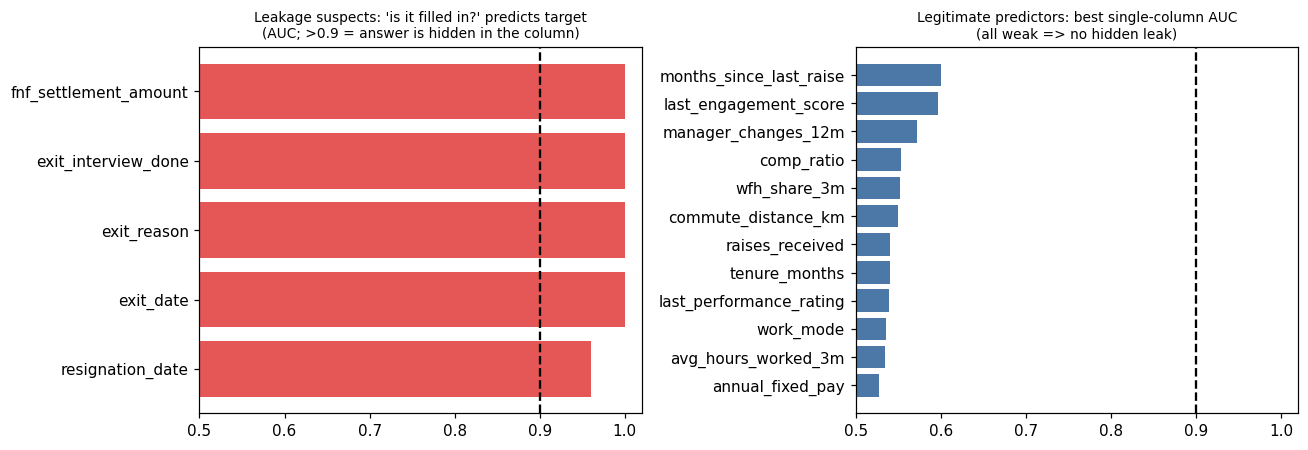

In [15]:
A.plot_leakage(A.missingness_indicator_power(raw, post), single);

## 9. Audit table (problem, where, how many rows, evidence, severity, treatment, reason)

In [16]:
audit_t, _, _ = A.build_audit_table(raw, D.load_sheet(C.SHEET_ATT), D.load_sheet(C.SHEET_PAY))
print(len(audit_t), 'distinct findings')
audit_t[['problem', 'affected_column_or_location', 'rows_affected', 'severity', 'proposed_treatment']]

17 distinct findings


                                             problem                                                                                              affected_column_or_location  rows_affected  \
0                     Post-outcome (leakage) columns          exit_date, resignation_date, exit_reason, exit_interview_done, fnf_settlement_amount, voluntary_left_within_12m            349   
1                          Exact duplicate snapshots                                                                                                              employee_id              6   
2                  Impossible value: negative tenure                                                                                                            tenure_months              4   
3        Impossible value: negative total experience                                                                                                   total_experience_years             10   
4   Impossible value: experience shorter

In [17]:
audit_t[['problem', 'evidence', 'reason']]

                                             problem                                                                                                                 evidence  \
0                     Post-outcome (leakage) columns  exit_date: filled for 100.0% of leavers and 0.0% of stayers (filled-in flag AUC=1.0); every non-null date is after o...   
1                          Exact duplicate snapshots   6 rows repeat another row in all columns; ids ['EMP-0060', 'EMP-0237', 'EMP-0238', 'EMP-0325', 'EMP-0483', 'EMP-0570']   
2                  Impossible value: negative tenure                                                              4 rows violate the rule (row_ids e.g. [109, 126, 313, 340])   
3        Impossible value: negative total experience                                                     10 rows violate the rule (row_ids e.g. [517, 872, 1106, 1651, 1815])   
4   Impossible value: experience shorter than tenure                                                       140 rows

## 10. Decision per column (feeds Day 2)

In [18]:
roles = A.column_roles(raw); roles.decision.value_counts()

decision
RETAIN       20
TRANSFORM    11
DROP         10
TARGET        1
Name: count, dtype: int64

In [19]:
roles[roles.decision.isin(['DROP', 'TARGET'])]

                       column decision                                             reason
0                      row_id     DROP                  identifier, no predictive meaning
1                 employee_id     DROP                  identifier, no predictive meaning
2            observation_date     DROP  time stamp of snapshot; time proxy / not a driver
34            left_within_12m   TARGET                              label; never an input
35  voluntary_left_within_12m     DROP                     confirmed post-outcome leakage
36                     source     DROP                dataset-origin tag, suspected proxy
37                  exit_date     DROP                     confirmed post-outcome leakage
38           resignation_date     DROP                     confirmed post-outcome leakage
39                exit_reason     DROP                     confirmed post-outcome leakage
40        exit_interview_done     DROP                     confirmed post-outcome leakage
41      fn

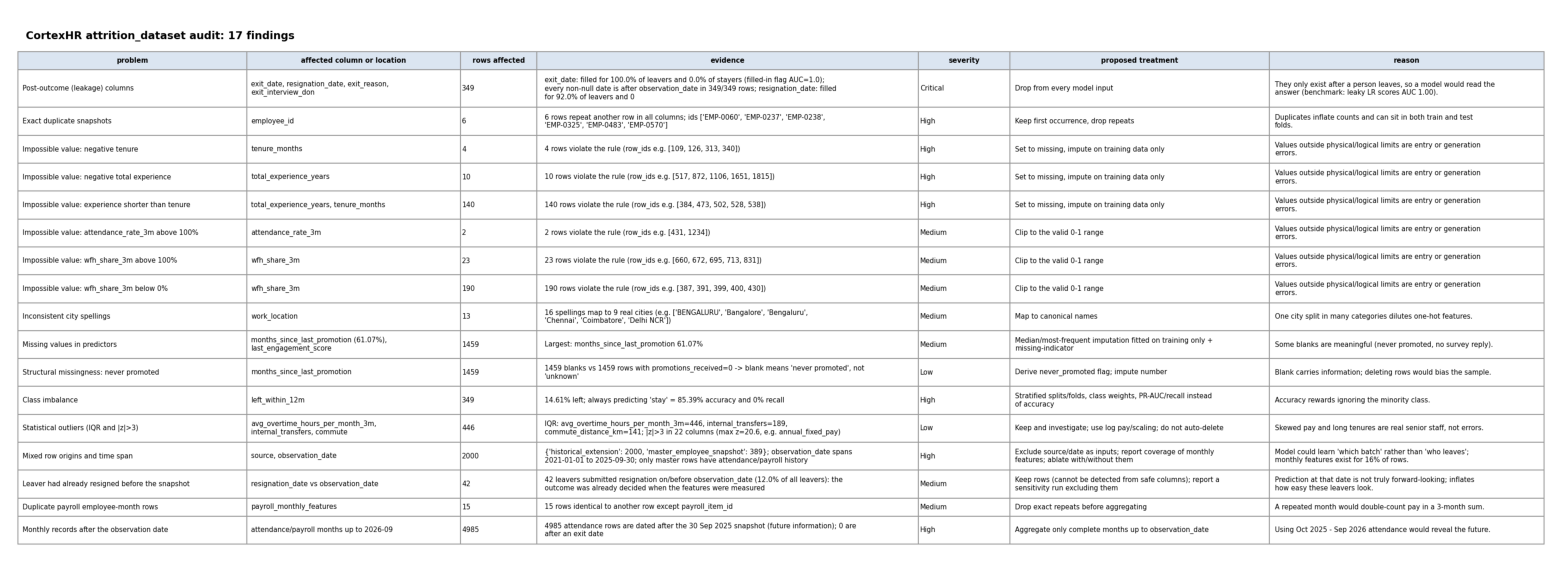

In [20]:
R.show_figure('audit_table', 14);

Full written report: `reports/data_audit_report.md`. Vault comparison (after commit): `reports/vault_comparison_cx01.md`.